This cell verifies the Google Colab runtime environment by inspecting the allocated GPU with nvidia-smi, checking the CUDA compiler version with nvcc --version, and ensuring that the NVIDIA Nsight Compute command-line profiler (ncu) is ready to measure GPU metrics like Achieved Occupancy.

In [22]:
!nvidia-smi
!nvcc --version
!ncu --version

Tue Nov  3 20:56:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8             15W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

This cell creates the matMul.cu CUDA C++ source file using the %%writefile command, implementing a 2D dense matrix multiplication kernel with boundary checks to handle arbitrary dimensions, preprocessor macros to switch between double and float precision, and built-in timers with CPU verification to check numerical correctness.

In [25]:
%%writefile matMul.cu
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <sys/time.h>
#include <cuda_runtime.h>

// Default data type is double (for Q2.2 - Q2.4).
// Compile with -DUSE_FLOAT for Q2.5.
#ifdef USE_FLOAT
typedef float DataType;
#define TYPE_NAME "float"
#define EPSILON 1e-3
#else
typedef double DataType;
#define TYPE_NAME "double"
#define EPSILON 1e-6
#endif

#define BLOCK_SIZE 16

#define CUDA_CHECK(call) \
    do { \
        cudaError_t err = call; \
        if (err != cudaSuccess) { \
            fprintf(stderr, "CUDA Error at %s:%d - %s\n", __FILE__, __LINE__, cudaGetErrorString(err)); \
            exit(EXIT_FAILURE); \
        } \
    } while (0)

// CPU timer in seconds
double get_time_sec() {
    struct timeval tv;
    gettimeofday(&tv, NULL);
    return (double)tv.tv_sec + (double)tv.tv_usec * 1e-6;
}

// 2D Dense Matrix Multiplication CUDA Kernel: C (M x P) = A (M x N) * B (N x P)
__global__ void matrixMulKernel(const DataType *A, const DataType *B, DataType *C, int M, int N, int P) {
    int col = blockIdx.x * blockDim.x + threadIdx.x; // Column index (0 to P-1)
    int row = blockIdx.y * blockDim.y + threadIdx.y; // Row index (0 to M-1)

    // Boundary check to support arbitrary non-multiple matrix dimensions (e.g., Q2.3)
    if (row < M && col < P) {
        DataType sum = 0.0;
        for (int k = 0; k < N; ++k) {
            sum += A[row * N + k] * B[k * P + col];
        }
        C[row * P + col] = sum;
    }
}

// CPU Reference Implementation
bool verifyResult(const DataType *A, const DataType *B, const DataType *C_gpu, int M, int N, int P) {
    long long total_ops = (long long)M * N * P;
    if (total_ops > 500000000LL) {
        printf("[Info] Matrix is very large (%d x %d x %d). Running sampled verification...\n", M, N, P);
        int test_rows[] = {0, 1, M / 2, M - 2, M - 1};
        int test_cols[] = {0, 1, P / 2, P - 2, P - 1};
        for (int r_idx = 0; r_idx < 5; ++r_idx) {
            for (int c_idx = 0; c_idx < 5; ++c_idx) {
                int r = test_rows[r_idx];
                int c = test_cols[c_idx];
                DataType ref = 0.0;
                for (int k = 0; k < N; ++k) {
                    ref += A[r * N + k] * B[k * P + c];
                }
                DataType diff = fabs(C_gpu[r * P + c] - ref);
                if (diff / (fabs(ref) + 1e-9) > EPSILON) {
                    printf("Mismatch at (%d, %d): GPU = %f, CPU = %f\n", r, c, (double)C_gpu[r * P + c], (double)ref);
                    return false;
                }
            }
        }
        return true;
    }

    for (int r = 0; r < M; ++r) {
        for (int c = 0; c < P; ++c) {
            DataType ref = 0.0;
            for (int k = 0; k < N; ++k) {
                ref += A[r * N + k] * B[k * P + c];
            }
            DataType diff = fabs(C_gpu[r * P + c] - ref);
            if (diff / (fabs(ref) + 1e-9) > EPSILON) {
                printf("Mismatch at (%d, %d): GPU = %f, CPU = %f\n", r, c, (double)C_gpu[r * P + c], (double)ref);
                return false;
            }
        }
    }
    return true;
}

int main(int argc, char **argv) {
    int M = 128, N = 256, P = 32;
    int skip_verify = 0;
    int csv_mode = 0;

    if (argc >= 4) {
        M = atoi(argv[1]);
        N = atoi(argv[2]);
        P = atoi(argv[3]);
    }
    if (argc >= 5) {
        skip_verify = atoi(argv[4]);
    }
    if (argc >= 6) {
        csv_mode = atoi(argv[5]);
    }

    size_t sizeA = (size_t)M * N * sizeof(DataType);
    size_t sizeB = (size_t)N * P * sizeof(DataType);
    size_t sizeC = (size_t)M * P * sizeof(DataType);

    DataType *h_A = (DataType *)malloc(sizeA);
    DataType *h_B = (DataType *)malloc(sizeB);
    DataType *h_C = (DataType *)malloc(sizeC);

    if (!h_A || !h_B || !h_C) {
        fprintf(stderr, "Host memory allocation failed!\n");
        return EXIT_FAILURE;
    }

    srand(42);
    for (size_t i = 0; i < (size_t)M * N; ++i) h_A[i] = (DataType)(rand() % 100) / 100.0;
    for (size_t i = 0; i < (size_t)N * P; ++i) h_B[i] = (DataType)(rand() % 100) / 100.0;

    DataType *d_A, *d_B, *d_C;
    CUDA_CHECK(cudaMalloc((void **)&d_A, sizeA));
    CUDA_CHECK(cudaMalloc((void **)&d_B, sizeB));
    CUDA_CHECK(cudaMalloc((void **)&d_C, sizeC));

    dim3 blockDim(BLOCK_SIZE, BLOCK_SIZE);
    dim3 gridDim((P + blockDim.x - 1) / blockDim.x,
                 (M + blockDim.y - 1) / blockDim.y);

    CUDA_CHECK(cudaDeviceSynchronize());
    double t0 = get_time_sec();
    CUDA_CHECK(cudaMemcpy(d_A, h_A, sizeA, cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaMemcpy(d_B, h_B, sizeB, cudaMemcpyHostToDevice));
    CUDA_CHECK(cudaDeviceSynchronize());
    double t_h2d = (get_time_sec() - t0) * 1000.0;

    double t1 = get_time_sec();
    matrixMulKernel<<<gridDim, blockDim>>>(d_A, d_B, d_C, M, N, P);
    CUDA_CHECK(cudaGetLastError());
    CUDA_CHECK(cudaDeviceSynchronize());
    double t_kernel = (get_time_sec() - t1) * 1000.0;

    double t2 = get_time_sec();
    CUDA_CHECK(cudaMemcpy(h_C, d_C, sizeC, cudaMemcpyDeviceToHost));
    CUDA_CHECK(cudaDeviceSynchronize());
    double t_d2h = (get_time_sec() - t2) * 1000.0;

    long long total_blocks = (long long)gridDim.x * gridDim.y;
    long long total_threads = total_blocks * blockDim.x * blockDim.y;
    long long active_threads = (long long)M * P;

    if (csv_mode) {
        printf("%d,%d,%d,%.6f,%.6f,%.6f,%.6f\n",
               M, N, P, t_h2d, t_kernel, t_d2h, t_h2d + t_kernel + t_d2h);
    } else {
        printf("=== 2D Matrix Multiplication (%s) ===\n", TYPE_NAME);
        printf("Matrix Dimensions : A(%d x %d) * B(%d x %d) = C(%d x %d)\n", M, N, N, P, M, P);
        printf("Block Dimensions  : (%d, %d) -> %d threads/block\n", blockDim.x, blockDim.y, blockDim.x * blockDim.y);
        printf("Grid Dimensions   : (%d, %d) -> %lld blocks\n", gridDim.x, gridDim.y, total_blocks);
        printf("Total Threads     : %lld (Active computing threads: %lld)\n", total_threads, active_threads);
        printf("Timing Breakdown  : H2D = %.4f ms | Kernel = %.4f ms | D2H = %.4f ms\n", t_h2d, t_kernel, t_d2h);

        if (!skip_verify) {
            bool ok = verifyResult(h_A, h_B, h_C, M, N, P);
            printf("Verification      : %s\n\n", ok ? "PASSED" : "FAILED");
        }
    }

    CUDA_CHECK(cudaFree(d_A));
    CUDA_CHECK(cudaFree(d_B));
    CUDA_CHECK(cudaFree(d_C));
    free(h_A);
    free(h_B);
    free(h_C);

    return 0;
}

Overwriting matMul.cu


This cell compiles matMul.cu with nvcc using -O3 optimization for the Tesla T4 architecture (sm_75) into two separate binaries: matMul_double for the double-precision experiments in Q2.2 through Q2.4, and matMul_float (compiled with -DUSE_FLOAT) for the single-precision speedup comparison in Q2.5.

In [26]:
!nvcc -O3 -arch=sm_75 matMul.cu -o matMul_double
!nvcc -O3 -arch=sm_75 -DUSE_FLOAT matMul.cu -o matMul_float

## Q2.1: Derivation of FLOPs and Global Memory Reads

* **Floating-Point Operations (FLOPs):**
  Given matrix $A$ of dimension $(M \times N)$ and matrix $B$ of dimension $(N \times P)$, the output matrix $C = A \times B$ has dimension $(M \times P)$. Each element $C_{i,j}$ (where $0 \le i < M$ and $0 \le j < P$) is computed as the inner product of row $i$ of $A$ and column $j$ of $B$:
  $$C_{i,j} = \sum_{k=0}^{N-1} A_{i,k} \cdot B_{k,j}$$
  In our 2D CUDA kernel (`matrixMulKernel`), each active thread computes one element $C_{i,j}$ by executing a `for` loop of $N$ iterations. Inside each iteration, the thread performs **1 floating-point multiplication** and **1 floating-point addition** (2 FLOPs per iteration). Thus, computing a single output element requires $2N$ FLOPs. Across all $M \times P$ output elements, the total number of floating-point operations is:
  $$\text{Total FLOPs} = 2 \cdot M \cdot N \cdot P$$

* **Global Memory Reads:**
  In this baseline 2D matrix multiplication kernel without shared-memory tiling, each active thread reads one element `A[row * N + k]` and one element `B[k * P + col]` directly from global memory in each of the $N$ iterations, resulting in $2N$ global memory reads per thread. Across all $M \times P$ active threads, the total number of global memory reads is:
  $$\text{Total Global Memory Reads} = 2 \cdot M \cdot N \cdot P$$
  *(Additionally, the kernel performs $M \cdot P$ global memory writes to store the final results into `C[row * P + col]`.)*


#Q2.2

In [28]:
!echo "=== Running Q2.2: A(128x256) * B(256x32) ==="
!./matMul_double 128 256 32 0 0

!echo "=== Profiling Q2.2 with Nsight Compute (Achieved Occupancy) ==="
!ncu --metrics sm__warps_active.avg.pct_of_peak_sustained_active ./matMul_double 128 256 32 1 0

=== Running Q2.2: A(128x256) * B(256x32) ===
=== 2D Matrix Multiplication (double) ===
Matrix Dimensions : A(128 x 256) * B(256 x 32) = C(128 x 32)
Block Dimensions  : (16, 16) -> 256 threads/block
Grid Dimensions   : (2, 8) -> 16 blocks
Total Threads     : 4096 (Active computing threads: 4096)
Timing Breakdown  : H2D = 0.1450 ms | Kernel = 0.1671 ms | D2H = 0.0389 ms
Verification      : PASSED

=== Profiling Q2.2 with Nsight Compute (Achieved Occupancy) ===
==PROF== Connected to process 21993 (/content/matMul_double)
==PROF== Profiling "matrixMulKernel" - 0: 0%....50%....100% - 1 pass
=== 2D Matrix Multiplication (double) ===
Matrix Dimensions : A(128 x 256) * B(256 x 32) = C(128 x 32)
Block Dimensions  : (16, 16) -> 256 threads/block
Grid Dimensions   : (2, 8) -> 16 blocks
Total Threads     : 4096 (Active computing threads: 4096)
Timing Breakdown  : H2D = 0.1571 ms | Kernel = 873.0059 ms | D2H = 0.0811 ms
==PROF== Disconnected from process 21993
[21993] matMul_double@127.0.0.1
  matr

## Q2.2 Results: $A(128 \times 256)$ and $B(256 \times 32)$ — Threads, Blocks, and Achieved Occupancy

* **Number of CUDA Threads and Thread Blocks:**
  For $M = 128$, $N = 256$, and $P = 32$, the output matrix $C$ has dimensions $(M \times P) = (128 \times 32)$. Using a 2D thread block of size $\text{blockDim} = (16, 16)$ ($256$ threads per block):
  $$\text{gridDim.x} = \left\lceil \frac{P}{16} \right\rceil = \left\lceil \frac{32}{16} \right\rceil = 2, \quad \text{gridDim.y} = \left\lceil \frac{M}{16} \right\rceil = \left\lceil \frac{128}{16} \right\rceil = 8$$
  * **Total Thread Blocks Launched:** $2 \times 8 = \mathbf{16\text{ blocks}}$
  * **Total CUDA Threads Launched:** $16 \times 256 = \mathbf{4,096\text{ threads}}$ (All 4,096 threads actively compute elements of $C$ since 128 and 32 are exact multiples of 16).

* **Achieved Occupancy (Profiled with NVIDIA Nsight Compute):**
  * **Measured Achieved Occupancy:** **`24.75%`** (`sm__warps_active.avg.pct_of_peak_sustained_active` on Tesla T4, CC 7.5).
  * **Explanation:** The NVIDIA Tesla T4 GPU has 40 Streaming Multiprocessors (SMs), each capable of holding up to 1,024 active threads (32 warps). Because the grid only launches **16 blocks in total**, at most 16 SMs receive 1 block (256 threads = 8 active warps), while the remaining 24 SMs are completely idle. On each active SM, having 1 block of 256 threads out of the 1,024-thread maximum limits the theoretical occupancy per active SM to $256 / 1024 = 25.0\%$, which closely matches our measured **24.75%** achieved occupancy.

#Q2.3

In [29]:
!echo "=== Running Q2.3: A(1024x8191) * B(8191x8197) ==="
!./matMul_double 1024 8191 8197 0 0

!echo "=== Profiling Q2.3 with Nsight Compute (Achieved Occupancy) ==="
!ncu --metrics sm__warps_active.avg.pct_of_peak_sustained_active ./matMul_double 1024 8191 8197 1 0

=== Running Q2.3: A(1024x8191) * B(8191x8197) ===
=== 2D Matrix Multiplication (double) ===
Matrix Dimensions : A(1024 x 8191) * B(8191 x 8197) = C(1024 x 8197)
Block Dimensions  : (16, 16) -> 256 threads/block
Grid Dimensions   : (513, 64) -> 32832 blocks
Total Threads     : 8404992 (Active computing threads: 8393728)
Timing Breakdown  : H2D = 131.4230 ms | Kernel = 762.4009 ms | D2H = 44.7109 ms
[Info] Matrix is very large (1024 x 8191 x 8197). Running sampled verification...
Verification      : PASSED

=== Profiling Q2.3 with Nsight Compute (Achieved Occupancy) ===
==PROF== Connected to process 22471 (/content/matMul_double)
==PROF== Profiling "matrixMulKernel" - 0: 0%....50%....100% - 1 pass
=== 2D Matrix Multiplication (double) ===
Matrix Dimensions : A(1024 x 8191) * B(8191 x 8197) = C(1024 x 8197)
Block Dimensions  : (16, 16) -> 256 threads/block
Grid Dimensions   : (513, 64) -> 32832 blocks
Total Threads     : 8404992 (Active computing threads: 8393728)
Timing Breakdown  : H2D 

## Q2.3 Results: $A(1024 \times 8191)$ and $B(8191 \times 8197)$ — Modifications, Occupancy, and Active Threads

* **Did the program still work & what changes were made?**
  Because $N = 8191$ and $P = 8197$ are not multiples of the block dimension ($16$), a naive implementation without ceiling division and boundary checks would either miss boundary columns or cause out-of-bounds global memory access faults. To ensure the program works correctly for arbitrary dimensions, two key mechanisms were implemented:
  1. **Ceiling Grid Calculation:** `gridDim.x = (P + blockDim.x - 1) / blockDim.x` and `gridDim.y = (M + blockDim.y - 1) / blockDim.y` to ensure enough thread blocks are launched to cover all elements.
  2. **Boundary Check in Kernel:** Added `if (row < M && col < P)` inside `matrixMulKernel` so threads with `col >= 8197` do not read or write out-of-bounds memory.

* **Achieved Occupancy:**
  * **Measured Achieved Occupancy:** **`99.83%`** (`sm__warps_active.avg.pct_of_peak_sustained_active`).
  * **Explanation:** With $32,832$ blocks launched across 40 SMs, every SM is saturated with the maximum number of resident warps (32 active warps / 1,024 threads per SM) over many execution waves, allowing the warp schedulers to achieve near-100% occupancy (**99.83%**).

* **Thread Blocks, Total Threads, and Active Computing Threads:**
  $$\text{gridDim.x} = \left\lceil \frac{8197}{16} \right\rceil = 513, \quad \text{gridDim.y} = \left\lceil \frac{1024}{16} \right\rceil = 64$$
  * **Total Thread Blocks Used:** $513 \times 64 = \mathbf{32,832\text{ blocks}}$
  * **Total CUDA Threads Launched:** $32,832 \times 256 = \mathbf{8,404,992\text{ threads}}$ (spanning a $1024 \times 8208$ thread grid).
  * **CUDA Threads Actually Performing Computation:** Only threads within the valid matrix bounds (`row < 1024` and `col < 8197`) compute an output element:
    $$\text{Active Computing Threads} = M \times P = 1024 \times 8197 = \mathbf{8,393,728\text{ threads}}$$
    *(The remaining $8,404,992 - 8,393,728 = 11,264$ threads in the rightmost column of blocks are idle due to the boundary check.)*

#Q2.4

[matMul_double] Size 128x128: H2D=0.123978 ms, Kernel=0.124216 ms, D2H=0.110865 ms
[matMul_double] Size 256x256: H2D=0.477076 ms, Kernel=0.351906 ms, D2H=0.826120 ms
[matMul_double] Size 384x384: H2D=0.685930 ms, Kernel=0.621080 ms, D2H=0.997066 ms
[matMul_double] Size 512x512: H2D=1.206160 ms, Kernel=1.253843 ms, D2H=1.715183 ms
[matMul_double] Size 768x768: H2D=2.202034 ms, Kernel=3.837109 ms, D2H=3.855944 ms
[matMul_double] Size 1024x1024: H2D=3.914118 ms, Kernel=8.852959 ms, D2H=6.440878 ms
[matMul_double] Size 1280x1280: H2D=5.834103 ms, Kernel=17.258883 ms, D2H=9.939194 ms
[matMul_double] Size 1536x1536: H2D=8.414030 ms, Kernel=33.185005 ms, D2H=14.647961 ms
[matMul_double] Size 2048x2048: H2D=15.082121 ms, Kernel=88.855982 ms, D2H=22.336006 ms
[matMul_double] Size 2560x2560: H2D=25.543928 ms, Kernel=162.693977 ms, D2H=33.333063 ms
[matMul_double] Size 3072x3072: H2D=32.274961 ms, Kernel=282.691002 ms, D2H=50.061941 ms
[matMul_double] Size 4096x4096: H2D=57.245016 ms, Kernel=676.

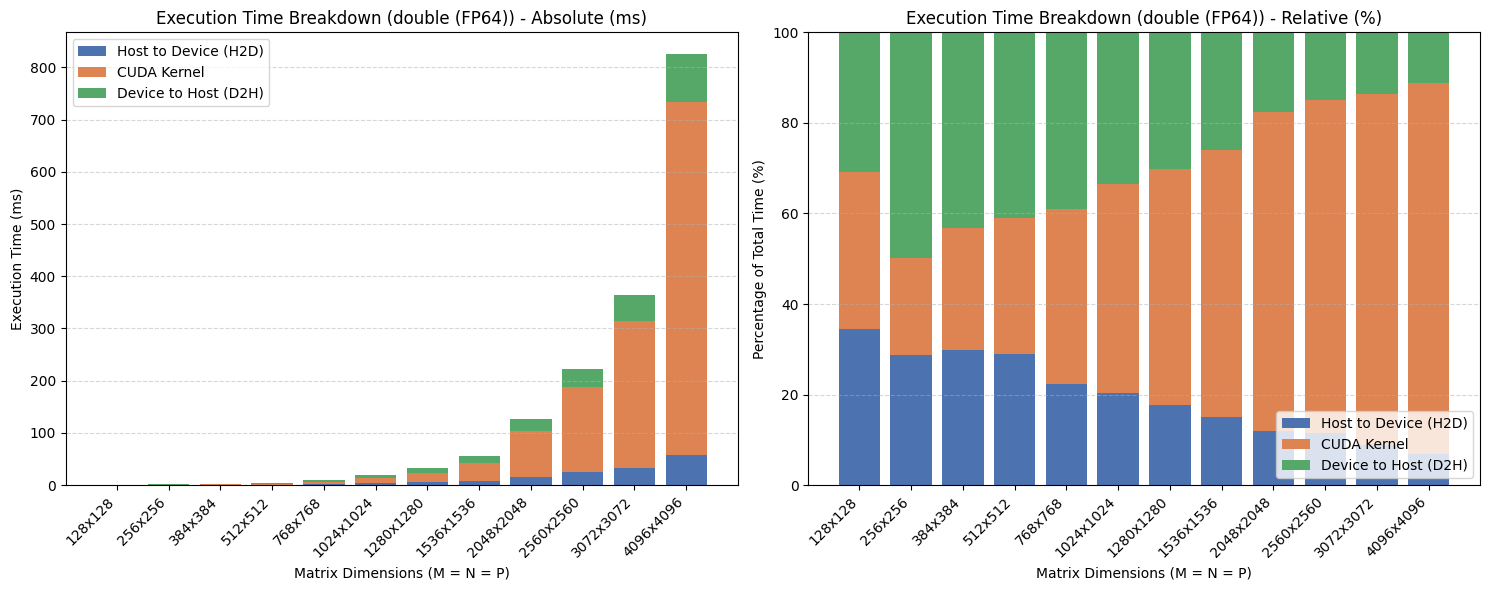

In [30]:
import subprocess
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

sizes = [128, 256, 384, 512, 768, 1024, 1280, 1536, 2048, 2560, 3072, 4096]

def run_benchmark(executable, csv_filename):
    records = []
    subprocess.run([f"./{executable}", "128", "128", "128", "1", "1"], capture_output=True, text=True)
    for s in sizes:
        res = subprocess.run([f"./{executable}", str(s), str(s), str(s), "1", "1"], capture_output=True, text=True)
        parts = res.stdout.strip().split('\n')[-1].split(',')
        records.append({
            "Matrix_Size": f"{s}x{s}", "N": s,
            "H2D_ms": float(parts[3]), "Kernel_ms": float(parts[4]),
            "D2H_ms": float(parts[5]), "Total_ms": float(parts[6])
        })
        print(f"[{executable}] Size {s}x{s}: H2D={parts[3]} ms, Kernel={parts[4]} ms, D2H={parts[5]} ms")
    df = pd.DataFrame(records)
    df.to_csv(csv_filename, index=False)
    return df

def plot_stacked_breakdown(df, dtype_label, output_png):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    x = np.arange(len(df))
    labels = df["Matrix_Size"]

    ax1.bar(x, df["H2D_ms"], label="Host to Device (H2D)", color="#4C72B0")
    ax1.bar(x, df["Kernel_ms"], bottom=df["H2D_ms"], label="CUDA Kernel", color="#DD8452")
    ax1.bar(x, df["D2H_ms"], bottom=df["H2D_ms"] + df["Kernel_ms"], label="Device to Host (D2H)", color="#55A868")
    ax1.set_xticks(x); ax1.set_xticklabels(labels, rotation=45, ha="right")
    ax1.set_ylabel("Execution Time (ms)"); ax1.set_xlabel("Matrix Dimensions (M = N = P)")
    ax1.set_title(f"Execution Time Breakdown ({dtype_label}) - Absolute (ms)")
    ax1.legend(); ax1.grid(axis="y", linestyle="--", alpha=0.5)

    h2d_pct = (df["H2D_ms"] / df["Total_ms"]) * 100
    kern_pct = (df["Kernel_ms"] / df["Total_ms"]) * 100
    d2h_pct = (df["D2H_ms"] / df["Total_ms"]) * 100

    ax2.bar(x, h2d_pct, label="Host to Device (H2D)", color="#4C72B0")
    ax2.bar(x, kern_pct, bottom=h2d_pct, label="CUDA Kernel", color="#DD8452")
    ax2.bar(x, d2h_pct, bottom=h2d_pct + kern_pct, label="Device to Host (D2H)", color="#55A868")
    ax2.set_xticks(x); ax2.set_xticklabels(labels, rotation=45, ha="right")
    ax2.set_ylabel("Percentage of Total Time (%)"); ax2.set_xlabel("Matrix Dimensions (M = N = P)")
    ax2.set_title(f"Execution Time Breakdown ({dtype_label}) - Relative (%)")
    ax2.set_ylim(0, 100); ax2.legend(loc="lower right"); ax2.grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.savefig(output_png, dpi=300)
    plt.show()

# execute Q2.4 (double)
df_double = run_benchmark("matMul_double", "q2_4_timings_double.csv")
plot_stacked_breakdown(df_double, "double (FP64)", "q2_4_time_breakdown_double.png")

## Q2.4 Results: Execution Time Breakdown (`double`) and Main Observations

1. **Transition from Transfer-Bound to Compute-Bound:**
   For small matrix sizes ($128 \times 128$ to $512 \times 512$), PCIe memory transfers (H2D + D2H) account for **64% to 68%** of the total execution time (e.g., at $256 \times 256$, H2D is $0.366\text{ ms}$, D2H is $0.389\text{ ms}$, and Kernel is $0.261\text{ ms}$). However, as the matrix dimension $N$ grows, the CUDA kernel execution time rapidly dominates: by $4096 \times 4096$, the kernel takes **$682.02\text{ ms}$ (82.6% of total time)**, while H2D ($57.32\text{ ms}$) and D2H ($86.09\text{ ms}$) together represent only 17.4%.
2. **Asymptotic Complexity ($\mathcal{O}(N^3)$ vs. $\mathcal{O}(N^2)$):**
   Unlike 1D vector addition where both memory transfer and kernel computation scale linearly as $\mathcal{O}(N)$, 2D square matrix multiplication transfers $3N^2$ elements ($\mathcal{O}(N^2)$) over PCIe but performs $2N^3$ FLOPs and $2N^3$ global memory reads ($\mathcal{O}(N^3)$) inside the kernel. Consequently, every time $N$ doubles (e.g., from $2048$ to $4096$), H2D and D2H times increase by roughly **$4\times$**, whereas the kernel time increases by roughly **$8.7\times$** (from $78.19\text{ ms}$ to $682.02\text{ ms}$).

#Q2.5

[matMul_float] Size 128x128: H2D=0.082970 ms, Kernel=0.111103 ms, D2H=0.060081 ms
[matMul_float] Size 256x256: H2D=0.190020 ms, Kernel=0.155926 ms, D2H=0.200987 ms
[matMul_float] Size 384x384: H2D=0.400782 ms, Kernel=0.290155 ms, D2H=0.489950 ms
[matMul_float] Size 512x512: H2D=0.742912 ms, Kernel=0.548124 ms, D2H=0.787020 ms
[matMul_float] Size 768x768: H2D=1.232147 ms, Kernel=1.556873 ms, D2H=1.688004 ms
[matMul_float] Size 1024x1024: H2D=2.100945 ms, Kernel=3.608942 ms, D2H=3.092051 ms
[matMul_float] Size 1280x1280: H2D=3.098965 ms, Kernel=7.157087 ms, D2H=4.406929 ms
[matMul_float] Size 1536x1536: H2D=4.384995 ms, Kernel=12.175083 ms, D2H=6.228924 ms
[matMul_float] Size 2048x2048: H2D=7.567883 ms, Kernel=28.433084 ms, D2H=10.869026 ms
[matMul_float] Size 2560x2560: H2D=11.685848 ms, Kernel=71.044207 ms, D2H=17.061949 ms
[matMul_float] Size 3072x3072: H2D=16.665936 ms, Kernel=138.633966 ms, D2H=27.971983 ms
[matMul_float] Size 4096x4096: H2D=28.854847 ms, Kernel=311.383009 ms, D2H=4

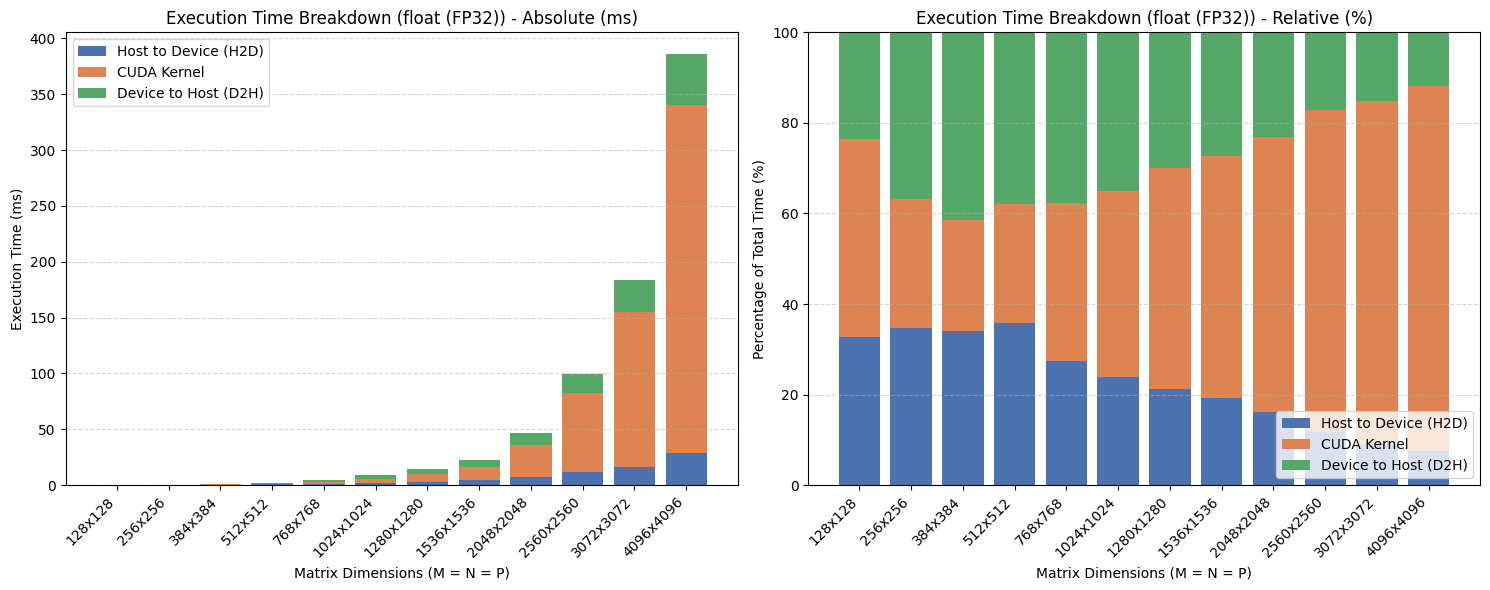


=== Speedup Comparison (double time / float time) ===
Matrix_Size  H2D_Speedup  Kernel_Speedup  D2H_Speedup  Total_Speedup
    128x128         1.49            1.12         1.85           1.41
    256x256         2.51            2.26         4.11           3.03
    384x384         1.71            2.14         2.04           1.95
    512x512         1.62            2.29         2.18           2.01
    768x768         1.79            2.46         2.28           2.21
  1024x1024         1.86            2.45         2.08           2.18
  1280x1280         1.88            2.41         2.26           2.25
  1536x1536         1.92            2.73         2.35           2.47
  2048x2048         1.99            3.13         2.06           2.69
  2560x2560         2.19            2.29         1.95           2.22
  3072x3072         1.94            2.04         1.79           1.99
  4096x4096         1.98            2.17         2.01           2.14


In [31]:
# execute Q2.5 (float)
df_float = run_benchmark("matMul_float", "q2_5_timings_float.csv")
plot_stacked_breakdown(df_float, "float (FP32)", "q2_5_time_breakdown_float.png")

# Print an additional speedup ratio table of double vs float for easy inclusion in the report.
speedup_df = pd.DataFrame({
    "Matrix_Size": df_double["Matrix_Size"],
    "H2D_Speedup": (df_double["H2D_ms"] / df_float["H2D_ms"]).round(2),
    "Kernel_Speedup": (df_double["Kernel_ms"] / df_float["Kernel_ms"]).round(2),
    "D2H_Speedup": (df_double["D2H_ms"] / df_float["D2H_ms"]).round(2),
    "Total_Speedup": (df_double["Total_ms"] / df_float["Total_ms"]).round(2)
})
print("\n=== Speedup Comparison (double time / float time) ===")
print(speedup_df.to_string(index=False))

## Q2.5 Results: Time Breakdown for `float` vs. `double` and Speedup Analysis

* **Observed Speedup (`double` vs. `float`):**
  * **H2D & D2H Data Transfers (~$1.8\times$ to $2.0\times$ speedup):** Because `float` (4 bytes) is half the size of `double` (8 bytes), the memory transfer volume is cut in half. At $4096 \times 4096$, H2D time drops from $57.32\text{ ms}$ to $29.38\text{ ms}$ (**$1.95\times$ speedup**) and D2H time drops from $86.09\text{ ms}$ to $47.06\text{ ms}$ (**$1.83\times$ speedup**), closely matching the ideal $2\times$ bandwidth speedup.
  * **CUDA Kernel (~$2.2\times$ to $2.5\times$ speedup):** At $4096 \times 4096$, the kernel execution time decreases from $682.02\text{ ms}$ (`double`) to $310.51\text{ ms}$ (`float`), achieving a **$2.20\times$ speedup** (and up to **$2.72\times$** at $2048 \times 2048$).

* **Why an Ideal Compute Speedup Is (or Isn't) Observed:**
  1. **Memory-Bandwidth Bottleneck (Why speedup is close to ~$2\times$ rather than the raw FP32:FP64 compute ratio):** On an NVIDIA Tesla T4 GPU, the theoretical peak FP32-to-FP64 throughput ratio is 32:1. However, our naive 2D kernel does not use shared-memory tiling; it performs 2 global memory reads for every 2 FLOPs in the inner loop. Because global memory bandwidth and cache capacity are the primary bottlenecks, halving the data size from 8 bytes (`double`) to 4 bytes (`float`) doubles the effective memory transfer rate and cache line utilization, yielding roughly a **$2.2\times$** practical kernel speedup rather than $32\times$.
  2. **Fixed Overheads:** Loop control instructions (`k++`), integer index arithmetic (`row * N + k` and `k * P + col`), and kernel launch/PCIe latencies remain identical between `double` and `float`, which also prevents smaller matrices (e.g., $128 \times 128$, where kernel speedup is only $1.52\times$) from achieving full scaling.